## Load python modules

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
from numpy import log as ln

plt.rcParams["figure.dpi"] = 100
plt.rc("savefig", dpi=600)
palette_colors = ["#3288bd", "#d53e4f", "#99d594", "#fc8d59"]
pi = math.pi
plt.rcParams["font.size"] = 14
plt.rcParams["font.sans-serif"]
plt.rcParams["text.usetex"] = True

# Analytical solutions

In [3]:
# Material and model parameters (Gc0, he and ls are set with the mesh data above)
E = 17e9  # Young’s modulus E (Pa)
nu = 0.2  # Poisson’s ratio
mu = 1e-8  # dynamic viscosity (Pa.s)
Q = 2e-3  # flow rate (m^2/s)
Gc0 = 120  # Griffith energy (Pa.m)
he = 0.5  # element size along the fracture path (m)
ls = 1.0  # phase-field length scale (m)
Gc = Gc0 * (3.0 * he / 8.0 / ls + 1.0)
print(Gc)
K_IC = (E * Gc / (1 - nu**2)) ** 0.5
E_prime = E / (1 - nu**2)
mu_prime = 12 * mu
K_prime = 4 * (2 / pi) ** 0.5 * K_IC
M_viscosity_DL = mu_prime * Q / (E_prime) * (E_prime / K_prime) ** 4
M_viscosity_Si = 1 / 30
delta_M = M_viscosity_DL / (1 + M_viscosity_DL / M_viscosity_Si) ** 0.5
##
K_m = K_prime / (E_prime ** (3 / 4) * Q ** (1 / 4) * mu_prime ** (1 / 4))
print(
    K_m
)  # Dimensionless toughness parameter: Toughness-dominated regime if K_m > 4.13
# critical pressure to initiate propagation of a fracture with length of 10m
a0 = 10.0
p_c = math.sqrt(Gc * E_prime / pi / a0)
print(p_c)

142.5
26.53445992048013
283414.0263672406


In [4]:
# Solution function
def f(xi_i):
    A = (1 - xi_i**2) ** 0.5
    B = 1 + A
    C = 1 - A
    arc_COS = np.arccos(xi_i)
    arc_SIN = np.arcsin(xi_i)
    ##########
    Omega_bar_k0 = (pi ** (1 / 3)) / 2 * (1 - xi_i**2)
    PI_k0 = (pi ** (1 / 3)) / 8
    gamma_k0 = 2 / (pi ** (2 / 3))
    ##########
    Omega_bar_k1 = (8 / (3 * pi ** (2 / 3))) * (
        2 * pi
        - 4 * xi_i * arc_SIN
        - (5 / 6 - ln(2)) * A
        - 3 / 2 * ln(abs(B**B / (C**C)))
    )
    PI_k1 = (8 / (3 * pi ** (2 / 3))) * (
        1 / 24 + ln(4 * A) - (3 * xi_i * arc_COS) / (4 * A)
    )
    gamma_k1 = -(32 * (1 + 6 * ln(2))) / (9 * pi ** (5 / 3))
    ##########
    Omega_bar = Omega_bar_k0 + delta_M * Omega_bar_k1
    PI = PI_k0 + delta_M * PI_k1
    gamma = gamma_k0 + delta_M * gamma_k1

    return xi_i, Omega_bar, PI, gamma


# Solutions
xi = np.linspace(0.0, 0.999, 100)
t = np.linspace(0.0, 100.0, 150)
opening = np.zeros((len(xi), len(t)))
pressure = np.zeros((len(xi), len(t)))
length = []
openingCenter = []
pressureCenter = []
tCenter = []
for j in range(len(t)):
    if j > 0:
        ti = t[j]
        L_k = (E_prime * Q * ti / (K_prime)) ** (2 / 3)
        V = Q * ti
        eps = V / (L_k**2)

        for i in range(len(xi)):
            xi_i = f(xi[i])[0]
            # print(xi_i)
            Omega_bar_i = f(xi[i])[1]
            PI_i = f(xi[i])[2]
            gamma_i = f(xi[i])[3]
            Omega_i = Omega_bar_i * gamma_i

            if xi_i == 0:
                tCenter.append(ti)
                openingCenter.append(eps * L_k * Omega_i)
                pressureCenter.append(eps * E_prime * PI_i)
                length.append(L_k * gamma_i)
            # if xi_i/max(xi) == 1:
            #     length.append(L_k*gamma_i)

            opening[i][j] = eps * L_k * Omega_i
            pressure[i][j] = eps * E_prime * PI_i

## Plot analytical solutions

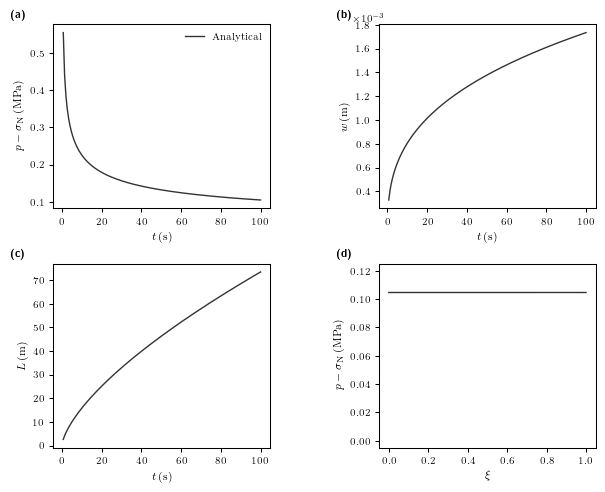

In [ ]:
t_target = 100.0
t_idx_ana = np.argmin(np.abs(t[1:] - t_target)) + 1
# 2x2 figure (Science double-column: 7 in wide)
fig, axes = plt.subplots(
    2, 2, figsize=(7, 5.5), gridspec_kw={"hspace": 0.3, "wspace": 0.5}
)

for ax in axes.flat:
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)
    ax.tick_params(direction="out", length=3, width=0.75, labelsize=7)

# Panel (a): pressure vs time
ax0 = axes[0, 0]
ax0.plot(
    tCenter,
    np.array(pressureCenter) / 1e6,
    color="#333333",
    linestyle="-",
    linewidth=1.0,
    label=r"$\mathrm{Analytical}$",
)
ax0.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax0.set_ylabel(r"$p-\sigma_{\mathrm{N}}\,\mathrm{(MPa)}$", fontsize=8)
ax0.legend(fontsize=7, frameon=False, loc="upper right")
ax0.text(-0.2, 1.02, r"\textbf{(a)}", transform=ax0.transAxes, fontsize=8, va="bottom")

# Panel (b): fracture opening vs time
ax1 = axes[0, 1]
ax1.plot(tCenter, openingCenter, color="#333333", linestyle="-", linewidth=1.0)
ax1.ticklabel_format(style="sci", scilimits=(-1, 2), axis="y")
ot = ax1.yaxis.get_offset_text()
ot.set_fontsize(7)
ot.set_x(-0.12)
ax1.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax1.set_ylabel(r"$w\,\mathrm{(m)}$", fontsize=8)
ax1.text(-0.2, 1.02, r"\textbf{(b)}", transform=ax1.transAxes, fontsize=8, va="bottom")

# Panel (c): crack length vs time
ax2 = axes[1, 0]
ax2.plot(tCenter, length, color="#333333", linestyle="-", linewidth=1.0)
ax2.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax2.set_ylabel(r"$L\,\mathrm{(m)}$", fontsize=8)
ax2.text(-0.2, 1.02, r"\textbf{(c)}", transform=ax2.transAxes, fontsize=8, va="bottom")

# Panel (d): pressure profile along fracture at t = 100 s
ax3 = axes[1, 1]
ax3.plot(
    xi, pressure[:, t_idx_ana] / 1e6, color="#333333", linestyle="-", linewidth=1.0
)
ax3.set_xlabel(r"$\xi$", fontsize=8)
ax3.set_ylabel(r"$p-\sigma_\mathrm{N}\,\mathrm{(MPa)}$", fontsize=8)
ax3.text(-0.2, 1.02, r"\textbf{(d)}", transform=ax3.transAxes, fontsize=8, va="bottom")
ax3.set_ylim(-0.005, 0.125)

# plt.savefig("KGD_toughness_analytical.pdf", bbox_inches="tight", dpi=300)
plt.show()

## Compare numerical results with analytical solutions

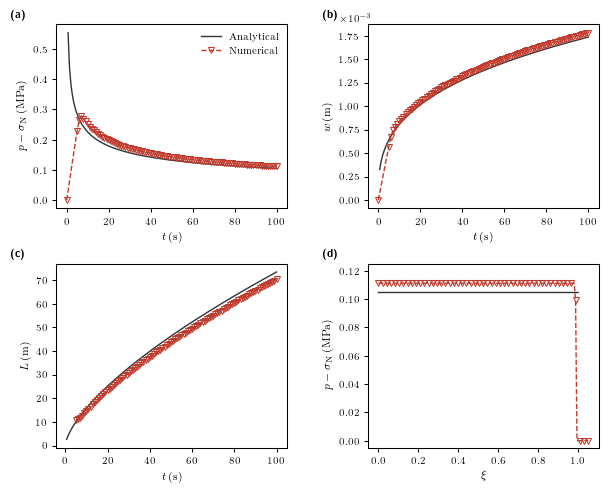

In [13]:
# Build the 2x2 figure from the exported CSVs from the phase-field simulation.
# This cell needs nothing from the cells above: it reads the four files and plots
# them, so the same figure can be produced anywhere the CSVs are available.
import matplotlib.pyplot as plt
import numpy as np

_rd = lambda f: np.genfromtxt(f, delimiter=",", names=True)
num_ts = _rd("../../data/K_vertex/numerical_timeseries.csv")
num_pr = _rd("../../data/K_vertex/numerical_profile_t100.csv")

# the masks the figure above applies
m_t = (num_ts["time_s"] >= 0) & (num_ts["time_s"] <= 100)
m_x = (num_pr["xi"] >= 0) & (num_pr["xi"] <= 1.05)

# panel tags fall back to plain text where LaTeX is not configured
_tag = (
    (lambda s: rf"\textbf{{({s})}}")
    if plt.rcParams["text.usetex"]
    else (lambda s: f"({s})")
)
ANA = dict(color="#333333", linestyle="-", linewidth=1.0)
NUM = dict(
    linestyle="--",
    color="#c0392b",
    linewidth=1.0,
    marker="v",
    markersize=4,
    markerfacecolor="none",
    markeredgewidth=0.75,
)

fig, axes = plt.subplots(
    2, 2, figsize=(7, 5.5), gridspec_kw={"hspace": 0.3, "wspace": 0.35}
)
for ax in axes.flat:
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)
    ax.tick_params(direction="out", length=3, width=0.75, labelsize=7)

# (a) pressure vs time
ax0 = axes[0, 0]
ax0.plot(
    tCenter,
    np.array(pressureCenter) / 1e6,
    label=r"$\mathrm{Analytical}$",
    **ANA,
)
ax0.plot(
    num_ts["time_s"][m_t],
    num_ts["net_pressure_Pa"][m_t] / 1e6,
    label=r"$\mathrm{Numerical}$",
    **NUM,
)
ax0.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax0.set_ylabel(r"$p-\sigma_{\mathrm{N}}\,\mathrm{(MPa)}$", fontsize=8)
ax0.legend(fontsize=7, frameon=False, loc="upper right")
ax0.text(-0.2, 1.02, _tag("a"), transform=ax0.transAxes, fontsize=8, va="bottom")

# (b) opening vs time
ax1 = axes[0, 1]
ax1.plot(tCenter, openingCenter, **ANA)
ax1.plot(num_ts["time_s"][m_t], num_ts["opening_m"][m_t], **NUM)
ax1.ticklabel_format(style="sci", scilimits=(-1, 2), axis="y")
ot = ax1.yaxis.get_offset_text()
ot.set_fontsize(7)
ot.set_x(-0.12)
ax1.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax1.set_ylabel(r"$w\,\mathrm{(m)}$", fontsize=8)
ax1.text(-0.2, 1.02, _tag("b"), transform=ax1.transAxes, fontsize=8, va="bottom")

# (c) crack length vs time
ax2 = axes[1, 0]
ax2.plot(tCenter, length, **ANA)
ax2.plot(num_ts["time_s"][m_t], num_ts["half_length_surface_m"][m_t], **NUM)
ax2.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax2.set_ylabel(r"$L\,\mathrm{(m)}$", fontsize=8)
ax2.text(-0.2, 1.02, _tag("c"), transform=ax2.transAxes, fontsize=8, va="bottom")

# (d) pressure profile at t = 100 s
ax3 = axes[1, 1]
ax3.plot(xi, pressure[:, t_idx_ana] / 1e6, **ANA)
ax3.plot(num_pr["xi"][m_x], num_pr["net_pressure_Pa"][m_x] / 1e6, markevery=3, **NUM)
ax3.set_xlabel(r"$\xi$", fontsize=8)
ax3.set_ylabel(r"$p-\sigma_\mathrm{N}\,\mathrm{(MPa)}$", fontsize=8)
ax3.text(-0.2, 1.02, _tag("d"), transform=ax3.transAxes, fontsize=8, va="bottom")
ax3.set_ylim(-0.005, 0.125)

plt.savefig("../../figures/KGD_toughness_results.pdf", bbox_inches="tight", dpi=300)
plt.show()